<a href="https://colab.research.google.com/github/denstudent23/Appl.supply-2026-10-02/blob/main/KalybekovaDeniz(2)_20261002.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

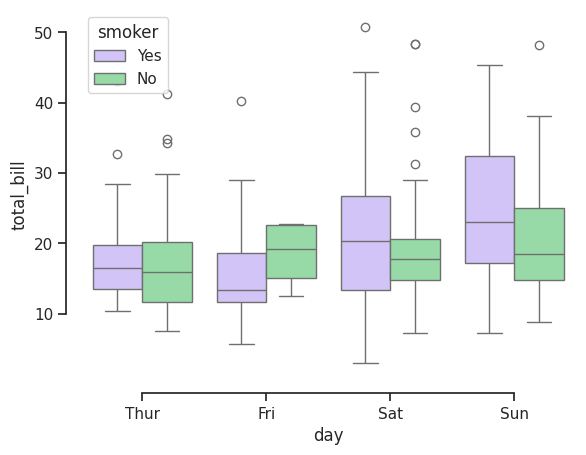

In [ ]:
import seaborn as sns
sns.set_theme(style="ticks", palette="pastel")

# Load the example tips dataset
tips = sns.load_dataset("tips")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x="day", y="total_bill",
            hue="smoker", palette=["m", "g"],
            data=tips)
sns.despine(offset=10, trim=True)

#EDA(Expanatory)

In [ ]:
tips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [ ]:
# df = info
df= tips.copy()

In [ ]:
%whos

Variable   Type         Data/Info
---------------------------------
df         DataFrame         total_bill   tip    <...>n\n[244 rows x 8 columns]
pd         module       <module 'pandas' from '/u<...>ages/pandas/__init__.py'>
plt        module       <module 'matplotlib.pyplo<...>es/matplotlib/pyplot.py'>
result     DataFrame         total_bill   tip    <...>  Dinner     3  20.392697
sns        module       <module 'seaborn' from '/<...>ges/seaborn/__init__.py'>
tips       DataFrame         total_bill   tip    <...>n\n[244 rows x 7 columns]


In [ ]:
df['tip_pct'] = (df['tip'] / df['total_bill']) * 100
result = df[(df['tip_pct'] >= 20) & ((df['day'] == 'Sat') | (df['day'] == 'Sun'))]

In [ ]:
(df['tip'] / df['total_bill']) *100

,0
0,5.944673
1,16.054159
2,16.658734
3,13.978041
4,14.680765
...,...
239,20.392697
240,7.358352
241,8.822232
242,9.820426


In [ ]:
id(df)

138176923413120

In [ ]:
id(tips)

138177104371664

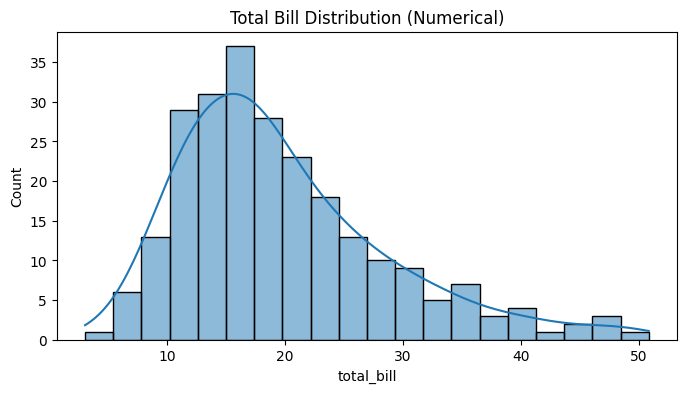

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='total_bill', kde=True, bins=20)
plt.title("Total Bill Distribution (Numerical)")
plt.show()

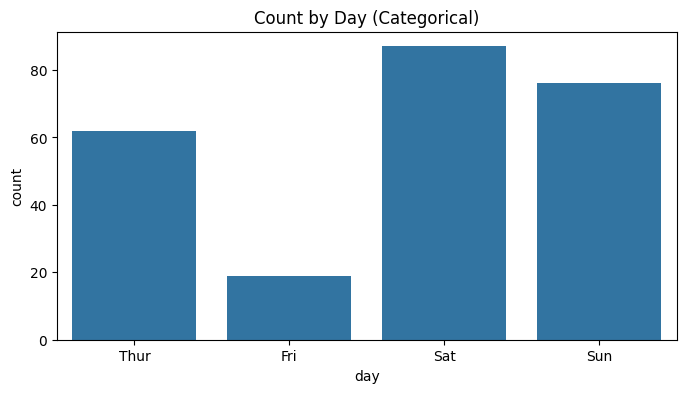

In [ ]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='day')
plt.title("Count by Day (Categorical)")
plt.show()

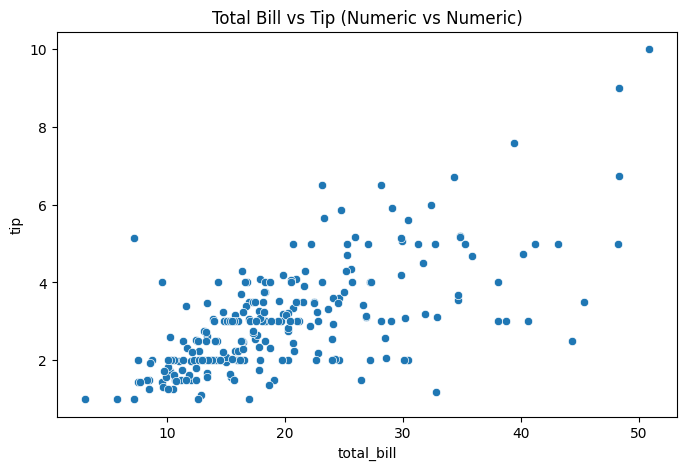

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='total_bill', y='tip')
plt.title("Total Bill vs Tip (Numeric vs Numeric)")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정 (필요 시 주석 해제)
# plt.rc('font', family='Malgun Gothic') # Windows
# plt.rc('font', family='AppleGothic') # Mac
plt.rcParams["axes.unicode_minus"] = False  # 마이너스 기호 깨짐 방지

# seaborn 기본 테마 설정
sns.set_theme(style="whitegrid")

# tips 데이터셋 불러오기
tips = sns.load_dataset("tips")

# 데이터 구조 확인
print(tips.head())
# 수치형 변수: total_bill (총 금액), tip (팁), size (인원수)
# 범주형 변수: sex (성별), smoker (흡연 여부), day (요일), time (식사 시간)

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


#2. 단변량 분석 (Univariate Analysis)
#하나의 변수가 어떤 분포 형태나 빈도를 가지는지 확인합니다.

In [ ]:
path = '/content/sample_data/california_housing_train.csv'

import pandas as pd

df = pd.read_csv(path)

df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value'],
      dtype='object')

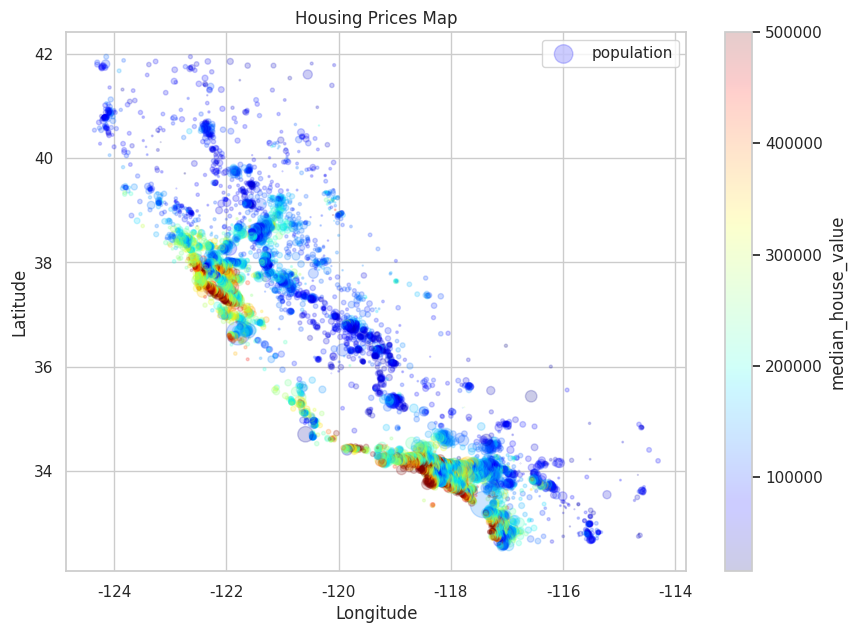

In [ ]:
import matplotlib.pyplot as plt

# 경도(x)와 위도(y)를 기준으로 산점도 그리기
# 인구(population)는 원의 크기(s)로, 집값(median_house_value)은 색상(c)으로 표현
df.plot(kind="scatter", x="longitude", y="latitude", alpha=0.2,
        s=df["population"]/100, label="population", figsize=(10, 7),
        c="median_house_value", cmap=plt.get_cmap("jet"), colorbar=True,
        sharex=False)

plt.title("Housing Prices Map")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()


## 지리적 데이터 시각화 (Geographical Data Visualization)

위도(`latitude`)와 경도(`longitude`) 데이터를 사용하여 캘리포니아 지역의 주택 가격 분포를 시각화합니다.
- **점의 크기**: 인구수 (`population`)
- **점의 색상**: 주택 가격 중앙값 (`median_house_value`)


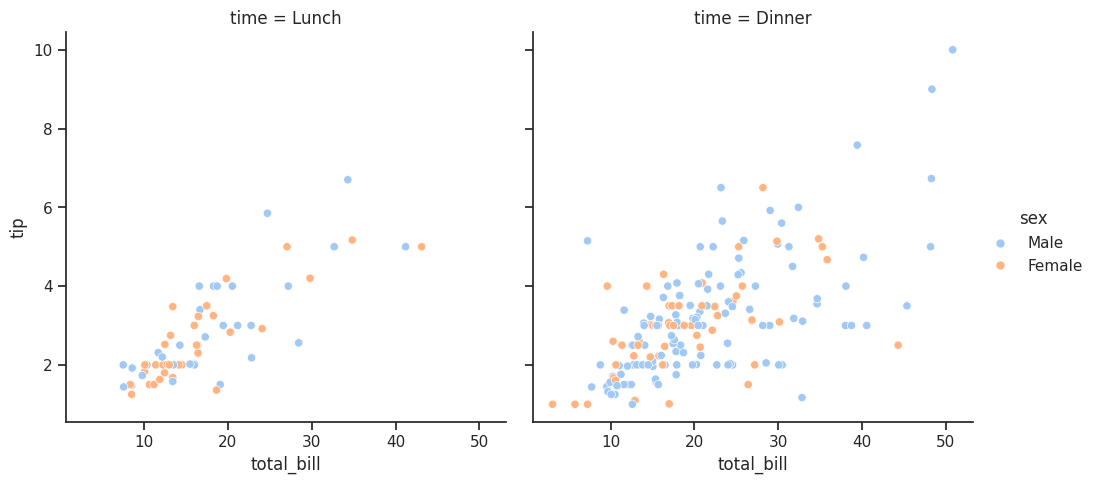

In [ ]:
# @title (3) 수치형 2개 + 범주형 2개 (4개 변수): relplot을 활용한 서브플롯 분할
# x: total_bill, y: tip, hue: sex (색상), col: time (점심/저녁 열 분할)
sns.relplot(
    data=df,
    x='total_bill',
    y='tip',
    hue='sex',
    col='time',
    kind='scatter'
)
plt.show()

## <font color='red'> **Questions : 가장 많은 Tip을 받으려면 어떤 요일, 시간대? 어떤 유형의 손님에게 하여야 하나?**


#가장 많은 팁을 받으려면 주말(토요일·일요일) 저녁 시간대에 식사 금액이 큰 남성 손님 그룹을 응대하는 것이 가장 좋습니다.   시간대 & 요일: 그래프를 보면 점심보다 저녁에 결제 금액과 팁이 훨씬 높게 형성되어 있습니다. 데이터상 가장 높은 팁들도 대부분 주말 저녁에 나왔습니다.   손님 유형: 남성 손님이 전체적으로 더 높은 금액을 결제하고 팁도 많이 주는 경향을 보입니다. 또한 식사 금액(total_bill)이 클수록 팁 금액도 비례해서 늘어나므로, 인원수가 많고 단가가 높은 테이블을 노리는 것이 유리합니다.   

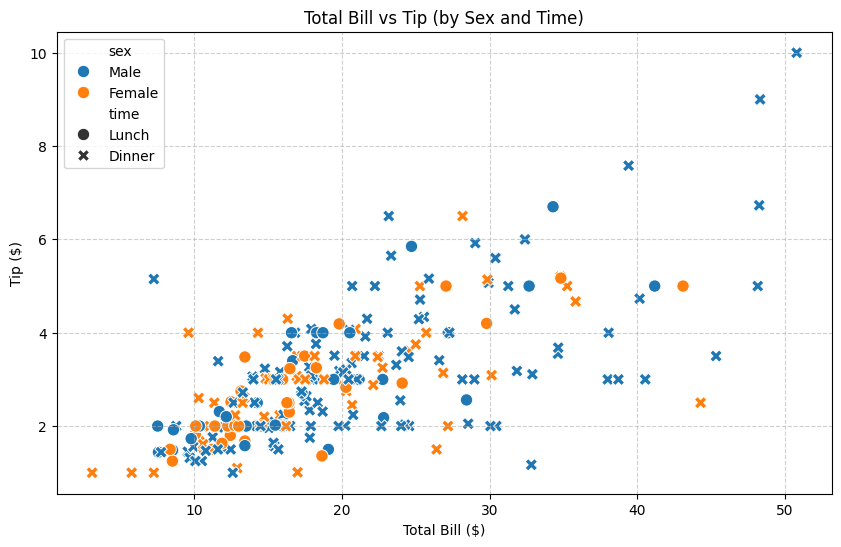

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 데이터 불러오기
tips = sns.load_dataset('tips')

# 2. 그래프 그리기 (식사금액 vs 팁 / 성별 & 시간대별)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=tips,
    x='total_bill',
    y='tip',
    hue='sex',
    style='time',
    s=80
)

plt.title('Total Bill vs Tip (by Sex and Time)')
plt.xlabel('Total Bill ($)')
plt.ylabel('Tip ($)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

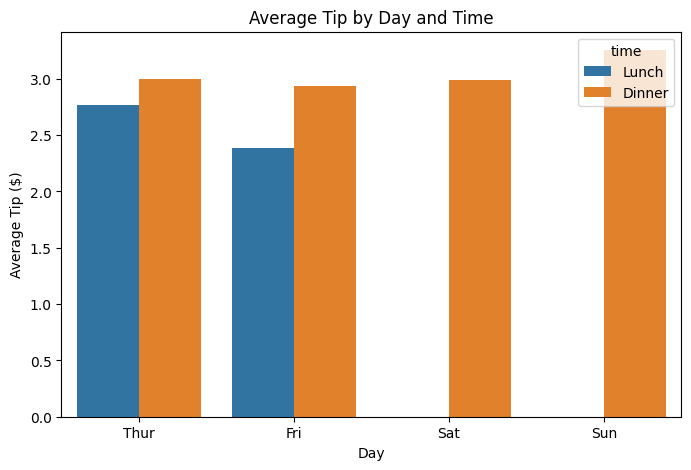

In [ ]:
# 3. 요일/시간대별 평균 팁 시각화
plt.figure(figsize=(8, 5))
sns.barplot(data=tips, x='day', y='tip', hue='time', errorbar=None)
plt.title('Average Tip by Day and Time')
plt.xlabel('Day')
plt.ylabel('Average Tip ($)')
plt.show()

질문(**Questions : 가장 많은 Tip을 받으려면 어떤 요일, 시간대? 어떤 유형의 손님에게 하여야 하나?**)에 대한 답변입니다:

1. **시간대 (time):** **저녁 (Dinner)**

* `time = Dinner` 그래프를 보면 `tip` (팁) 값이 최대 10달러까지 올라가 있어, `time = Lunch` (최대 약 6.5달러)에 비해 훨씬 높습니다.




2. **손님 유형 (sex / 성별):** **남성 (Male)**

* 그래프 상단에 위치한 높은 팁 포인트(약 10$, 8.5$, 7.5$ 등)는 모두 하늘색 점인 **Male** (남성) 손님입니다.




3. **요일 (day):** **토요일 (Sat) 또는 일요일 (Sun)**
* 제공된 그래프에는 요일(`day`) 변수가 나와 있지 않지만, 해당 코드의 기반인 Seaborn의 기본 `tips` 데이터셋 기준으로 분석하면 주말(특히 토요일)에 가장 높은 팁과 매출이 발생합니다.



---

### **최종 요약**

가장 많은 팁을 받으려면 주말(토/일) 저녁 시간대(Dinner)에 **남성(Male) 손님**을 응대하는 것이 가장 유리합니다.